# 06_track1_models: Track 1, predicting High-priority tickets at creation
Goal: flag priority 1 and 2 tickets when they are opened, using only fields known at that moment (asset and time). Inputs: `data/processed/track1_train.pkl` (October 2013 to January 2014) and `track1_test.pkl` (1 February to 16 March 2014), from `05_split_features`. Aggregates only. The tuning cells take several minutes.

**Contents**
- Sections 1 to 7: models, tuning, choice of model and threshold, headline result.
- Sections 8 to 12: uncertainty, operating points, rule baselines, segments, a break-fix check.
- Sections 13 to 15: what the model uses, the precision-recall figure, saving the model.
- Sections 16 to 18: why test recall is below validation, rolling-origin comparison, sensitivity to unconfirmed fields.
- Section 19: conclusion. Appendix A: history features (not adopted).

A four-class priority tagger (P2 to P5) for every ticket, which builds on this setup, is in `09_track3_triage`, section 5 (Objective 3).

**Headline:** logistic regression on asset and time fields catches 67 of 115 High tickets (recall 0.583) with about 5 alerts a day (precision 0.298); ROC-AUC 0.934, average precision 0.315 against a 0.011 base rate.

## 1. Setup: libraries and training data

In [1]:
import os, sys, time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append("../src")
from features import ci_name, set_a, set_b, unsure_timing

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report,
                             precision_recall_curve, confusion_matrix)

train = pd.read_pickle("../data/processed/track1_train.pkl")
y_train = train["High"]
print(train.shape, "| month present:", "month" in train.columns)

(30845, 29) | month present: False


<details>
<summary><b>Code notes, line by line</b></summary>

- `import os, sys, time, joblib, numpy, pandas, matplotlib` : Paths, timing, saving the model, arrays, data frames and plots.
- `from features import ci_name, set_a, set_b, unsure_timing` : Feature lists from src/features.py (written in 05).
- `from sklearn.base import clone` : Makes an unfitted copy of a model with the same settings.
- `ColumnTransformer, Pipeline, OneHotEncoder, StandardScaler` : Pre-processing: encode categories (and scale numbers in Appendix A) inside one pipeline.
- `GridSearchCV, TimeSeriesSplit` : Hyper-parameter search with time-ordered cross-validation.
- `compute_sample_weight` : Weights that give the rare High class as much total weight as the common class.
- `LogisticRegression, DecisionTree, RandomForest, GradientBoosting, XGBClassifier` : The five algorithms compared.
- `from sklearn.metrics import ...` : Accuracy, recall, precision, F1, ROC-AUC, average precision, reports, the PR curve and the confusion matrix.
- `train = pd.read_pickle(...); y_train = train["High"]` : Training months and target.
- `print(train.shape, "| month present:", ...)` : Confirms month is not a column (test months never occur in training).

</details>

## 2. Candidate models and tuning grids
Five algorithms with small grids; XGBoost gets a wider grid (64 settings). Categories are one-hot encoded, with values seen fewer than 30 times in training pooled as infrequent.

In [2]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=2000),
        {"clf__C": [0.01, 0.1, 1, 10]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=42),
        {"clf__max_depth": [3, 5, 8], "clf__min_samples_leaf": [20, 50]}),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
        {"clf__max_depth": [6, 10], "clf__min_samples_leaf": [5, 20]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=42),
        {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.05, 0.1], "clf__max_depth": [2, 3]}),
    "XGBoost": (XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=42, n_jobs=-1),
        {"clf__max_depth": [3, 5],"clf__learning_rate": [0.03, 0.1],"clf__min_child_weight": [1, 10],"clf__n_estimators": [200, 400],"clf__subsample": [0.8],"clf__colsample_bytree": [0.6, 1.0],"clf__reg_lambda": [1, 10]})
}

def make_pipe(cols, clf):
    enc = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30)
    return Pipeline([("pre", ColumnTransformer([("cat", enc, cols)])), ("clf", clf)])

<details>
<summary><b>Code notes, line by line</b></summary>

- `models = {name: (estimator, grid)}` : Each algorithm with the settings to try; keys like clf__C address the 'clf' step of the pipeline.
- `LogisticRegression ... {"clf__C": [0.01, 0.1, 1, 10]}` : C is the inverse of regularisation strength: smaller C = simpler model.
- `DecisionTree ... max_depth, min_samples_leaf` : Tree depth and the minimum tickets per leaf, both limit overfitting.
- `RandomForest(n_estimators=200, ...)` : 200 trees averaged; depth and leaf size tuned.
- `GradientBoosting ... n_estimators, learning_rate, max_depth` : Trees added one at a time, each correcting the last.
- `XGBClassifier ... (64 settings)` : A faster boosting library with a wider grid: depth, learning rate, child weight, trees, row and column sampling, L2 penalty.
- `def make_pipe(cols, clf):` : Builds encoder + model as one pipeline, so encoding is learned only from each training fold.
- `OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30)` : One column per value; values seen fewer than 30 times are pooled as 'infrequent', and unseen test values go to that pool.

</details>

## 3. Tune on the training months (time-ordered cross-validation)
Set B: asset and time fields. Balanced sample weights handle the class imbalance; models are ranked by average precision.

In [3]:
def tune(cols):
    X = train[cols].astype(str)
    w = compute_sample_weight("balanced", y_train)
    cv = TimeSeriesSplit(n_splits=3)
    fitted = {}
    for name, (clf, grid) in models.items():
        t0 = time.time()
        gs = GridSearchCV(make_pipe(cols, clf), grid, cv=cv,
                          scoring="average_precision", n_jobs=1, refit=True)
        gs.fit(X, y_train, clf__sample_weight=w)
        fitted[name] = gs
        print(f"{name}: CV AP {gs.best_score_:.3f} | {gs.best_params_} | {time.time() - t0:.0f}s")
    return fitted

print("Table 3. Five algorithms tuned on Set B: best CV average precision, settings and run time")
fit_b = tune(set_b)   # honest feature set: asset + time fields only

Table 3. Five algorithms tuned on Set B: best CV average precision, settings and run time
Logistic Regression: CV AP 0.451 | {'clf__C': 0.01} | 4s
Decision Tree: CV AP 0.405 | {'clf__max_depth': 8, 'clf__min_samples_leaf': 20} | 5s
Random Forest: CV AP 0.428 | {'clf__max_depth': 10, 'clf__min_samples_leaf': 5} | 15s
Gradient Boosting: CV AP 0.442 | {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 100} | 34s
XGBoost: CV AP 0.455 | {'clf__colsample_bytree': 0.6, 'clf__learning_rate': 0.03, 'clf__max_depth': 5, 'clf__min_child_weight': 1, 'clf__n_estimators': 200, 'clf__reg_lambda': 1, 'clf__subsample': 0.8} | 174s


<details>
<summary><b>Code notes, line by line</b></summary>

- `def tune(cols):` : Tunes all five algorithms on one feature set.
- `X = train[cols].astype(str)` : Features as text categories.
- `w = compute_sample_weight("balanced", y_train)` : Each High ticket weighs about 57 times a normal ticket, so both classes count equally.
- `cv = TimeSeriesSplit(n_splits=3)` : Three folds that always validate on months after the training months.
- `GridSearchCV(make_pipe(...), grid, cv=cv, scoring="average_precision", refit=True)` : Tries every setting, ranks them by average precision (suits rare classes), then refits the best on all training months.
- `gs.fit(X, y_train, clf__sample_weight=w)` : Passes the weights to the model step.
- `print(f"{name}: CV AP ...")` : Best CV score, best settings and run time per algorithm.
- `fit_b = tune(set_b)` : Runs the search on Set B (asset and time fields).

</details>

**Result.** On the training months, XGBoost has the best CV average precision (0.455), then logistic regression (0.451), gradient boosting (0.442), random forest (0.428) and the decision tree (0.405) (Table 3). Logistic regression prefers strong regularisation (C = 0.01). All five are far above the 0.018 base rate.

## 4. Test-period results for all five models

In [4]:
test = pd.read_pickle("../data/processed/track1_test.pkl")
y_test = test["High"]
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

def evaluate(fitted, cols):
    """One row per algorithm, plus the classification report of the best model by CV average precision."""
    Xtr, Xte = train[cols].astype(str), test[cols].astype(str)
    rows = []
    for name, gs in fitted.items():
        m = gs.best_estimator_
        pred_tr, pred_te = m.predict(Xtr), m.predict(Xte)
        proba = m.predict_proba(Xte)[:, 1]
        rows.append({
            "Model": name,
            "CV AP (train)": gs.best_score_,
            "Train accuracy": accuracy_score(y_train, pred_tr),
            "Test accuracy": accuracy_score(y_test, pred_te),
            "Recall (High)": recall_score(y_test, pred_te),
            "Precision (High)": precision_score(y_test, pred_te, zero_division=0),
            "F1 (High)": f1_score(y_test, pred_te),
            "ROC-AUC": roc_auc_score(y_test, proba),
            "Avg precision": average_precision_score(y_test, proba),
        })
    best = max(fitted, key=lambda k: fitted[k].best_score_)
    report = classification_report(y_test, fitted[best].best_estimator_.predict(Xte),
                                   target_names=["Not High", "High"], digits=3, zero_division=0)
    return pd.DataFrame(rows).set_index("Model").round(3), best, report

res_b, best_b, rep_b = evaluate(fit_b, set_b)
print(f"Table 4a. Set B (asset and time fields), test period | test High {int(y_test.sum())} of {len(y_test)} | "
      f"always-not-High accuracy {1 - y_test.mean():.3f} | random-model average precision {y_test.mean():.3f}")
display(res_b)
print("Table 4b. Classification report, best model by CV average precision:", best_b)
print(rep_b)

Table 4a. Set B (asset and time fields), test period | test High 115 of 10229 | always-not-High accuracy 0.989 | random-model average precision 0.011


,CV AP (train),Train accuracy,Test accuracy,Recall (High),Precision (High),F1 (High),ROC-AUC,Avg precision
Model,,,,,,,,
Logistic Regression,0.451,0.937,0.929,0.722,0.106,0.185,0.934,0.315
Decision Tree,0.405,0.958,0.965,0.643,0.191,0.295,0.887,0.322
Random Forest,0.428,0.968,0.971,0.600,0.217,0.319,0.941,0.336
Gradient Boosting,0.442,0.953,0.954,0.661,0.150,0.245,0.930,0.306
XGBoost,0.455,0.953,0.950,0.687,0.141,0.234,0.934,0.321


Table 4b. Classification report, best model by CV average precision: XGBoost
              precision    recall  f1-score   support

    Not High      0.996     0.953     0.974     10114
        High      0.141     0.687     0.234       115

    accuracy                          0.950     10229
   macro avg      0.569     0.820     0.604     10229
weighted avg      0.987     0.950     0.966     10229



<details>
<summary><b>Code notes, line by line</b></summary>

- `test = pd.read_pickle(...); y_test = test["High"]` : The test period.
- `pd.set_option(...)` : Wider display so tables do not wrap.
- `def evaluate(fitted, cols):` : Scores every tuned model on the test period.
- `pred_tr, pred_te = m.predict(Xtr), m.predict(Xte)` : Class predictions at the default 0.5 cut-off.
- `proba = m.predict_proba(Xte)[:, 1]` : Probability of High, used for ROC-AUC and average precision (threshold-free).
- `rows.append({... "Train accuracy", "Test accuracy", ...})` : Train vs test accuracy shows overfitting; recall, precision and F1 are for the High class.
- `best = max(fitted, key=lambda k: fitted[k].best_score_)` : Model with the best CV average precision.
- `classification_report(...)` : Per-class precision, recall and F1 for that model.
- `res_b, best_b, rep_b = evaluate(fit_b, set_b); display(res_b)` : Table of all five models and the report.

</details>

**Note.** XGBoost reaches CV AP 0.455 against 0.451 for logistic regression (Table 3), and test AP 0.321 against 0.315 (Table 4a): a tie, well within fold-to-fold variation (about 0.04). Random forest has the highest test AP (0.336) but a lower CV score (0.428), so it is not chosen on test results. Accuracy is not a useful measure here: always predicting "not High" scores 0.989 (first line of Table 4a), above every model. The precision, recall and F1 columns, and Table 4b, use each model's default 0.5 cut-off; the alert threshold is set in section 6.

## 5. Contrast: Set A (adds Impact and Urgency), not a model result
Priority is a lookup of Impact and Urgency: no Impact x Urgency pair maps to more than one priority (`02_ingest_and_profile`, section 8). Set A therefore only shows the models relearning the priority matrix.

In [5]:
print("Table 5a. Five algorithms tuned on Set A (adds Impact and Urgency)")
fit_a = tune(set_a)
res_a, best_a, rep_a = evaluate(fit_a, set_a)
print("Table 5b. Set A, test period: contrast only, not a model result")
display(res_a)

Table 5a. Five algorithms tuned on Set A (adds Impact and Urgency)
Logistic Regression: CV AP 1.000 | {'clf__C': 0.01} | 3s
Decision Tree: CV AP 0.994 | {'clf__max_depth': 3, 'clf__min_samples_leaf': 20} | 6s
Random Forest: CV AP 1.000 | {'clf__max_depth': 6, 'clf__min_samples_leaf': 5} | 19s
Gradient Boosting: CV AP 1.000 | {'clf__learning_rate': 0.1, 'clf__max_depth': 2, 'clf__n_estimators': 200} | 41s
XGBoost: CV AP 1.000 | {'clf__colsample_bytree': 0.6, 'clf__learning_rate': 0.03, 'clf__max_depth': 3, 'clf__min_child_weight': 1, 'clf__n_estimators': 200, 'clf__reg_lambda': 1, 'clf__subsample': 0.8} | 182s
Table 5b. Set A, test period: contrast only, not a model result


,CV AP (train),Train accuracy,Test accuracy,Recall (High),Precision (High),F1 (High),ROC-AUC,Avg precision
Model,,,,,,,,
Logistic Regression,1.000,1.0,1.000,0.965,1.000,0.982,1.000,0.991
Decision Tree,0.994,1.0,0.999,0.965,0.982,0.974,0.987,0.955
Random Forest,1.000,1.0,1.000,0.965,1.000,0.982,1.000,0.990
Gradient Boosting,1.000,1.0,1.000,0.965,0.991,0.978,0.983,0.966
XGBoost,1.000,1.0,0.999,0.965,0.982,0.974,1.000,0.990


<details>
<summary><b>Code notes, line by line</b></summary>

- `fit_a = tune(set_a)` : Same search with Impact and Urgency added (Set A).
- `res_a, best_a, rep_a = evaluate(fit_a, set_a)` : Test scores; near-perfect results show leakage, not skill.

</details>

**Result.** CV average precision is 0.994 to 1.000 for every model (Table 5a), and test AP 0.955 to 0.991 with precision up to 1.000 (Table 5b): with Impact and Urgency the task is trivial, which is why they are excluded from the headline features.

## 6. Choose the model and the alert threshold (validation on January)
Tie-break: if the top model is within 0.01 CV AP of logistic regression, logistic regression is kept, as it is simpler and its coefficients explain the predictions (added after the wider XGBoost grid was run). The chosen model is refitted on October to December; the threshold is the highest-precision cut-off that reaches 70% recall on January.

In [6]:
cv_ap = {k: v.best_score_ for k, v in fit_b.items()}
top = max(cv_ap, key=cv_ap.get)
# Tie-break: if the top model is within 0.01 CV AP of logistic regression, keep logistic regression
best_name = "Logistic Regression" if cv_ap[top] - cv_ap["Logistic Regression"] < 0.01 else top
print("Table 6. Model choice and alert threshold (threshold set on January)")
print(f"Top by CV AP: {top} ({cv_ap[top]:.3f}) | chosen: {best_name} ({cv_ap[best_name]:.3f})")

fit_part = train[train["Open_Time"] < "2014-01-01"]
val_part = train[train["Open_Time"] >= "2014-01-01"]

m_val = clone(fit_b[best_name].best_estimator_)
m_val.fit(fit_part[set_b].astype(str), fit_part["High"],
          clf__sample_weight=compute_sample_weight("balanced", fit_part["High"]))

p_val = m_val.predict_proba(val_part[set_b].astype(str))[:, 1]
prec, rec, thr = precision_recall_curve(val_part["High"], p_val)

TARGET_RECALL = 0.70
ok = np.where(rec[:-1] >= TARGET_RECALL)[0]
best_i = ok[np.argmax(prec[:-1][ok])]
threshold = float(thr[best_i])
print(f"Threshold {threshold:.3f} -> validation recall {rec[best_i]:.2f}, precision {prec[best_i]:.2f}")

Table 6. Model choice and alert threshold (threshold set on January)
Top by CV AP: XGBoost (0.455) | chosen: Logistic Regression (0.451)
Threshold 0.678 -> validation recall 0.70, precision 0.27


<details>
<summary><b>Code notes, line by line</b></summary>

- `cv_ap = {k: v.best_score_ ...}; top = max(cv_ap, key=cv_ap.get)` : Best CV average precision per algorithm and the overall top.
- `best_name = "Logistic Regression" if cv_ap[top] - cv_ap["Logistic Regression"] < 0.01 else top` : Tie-break: keep logistic regression when within 0.01 of the top (simpler, explainable).
- `fit_part / val_part` : October-December to fit, January to choose the threshold.
- `m_val = clone(...); m_val.fit(fit_part..., clf__sample_weight=...)` : Refits the chosen settings on October to December only, so January is unseen.
- `p_val = m_val.predict_proba(val_part...)[:, 1]` : January probabilities.
- `prec, rec, thr = precision_recall_curve(...)` : Precision and recall at every possible threshold.
- `ok = np.where(rec[:-1] >= TARGET_RECALL)[0]` : Thresholds that reach 70% recall (the last curve point has no threshold, hence [:-1]).
- `best_i = ok[np.argmax(prec[:-1][ok])]; threshold = float(thr[best_i])` : Among those, the one with the highest precision.

</details>

**Result.** XGBoost is top by CV AP but within 0.01 of logistic regression, so logistic regression is kept. Refitted on October to December, it reaches recall 0.70 on January at a threshold of 0.678, with precision 0.27 (Table 6).

## 7. Headline test result at the chosen threshold

In [7]:
final = fit_b[best_name].best_estimator_
p_te = final.predict_proba(test[set_b].astype(str))[:, 1]
pred = (p_te >= threshold).astype(int)

print(f"Table 7a. Confusion matrix at threshold {threshold:.3f}, test period (rows: actual Not High, High; columns: predicted)")
print(confusion_matrix(test["High"], pred))
print("Table 7b. Classification report at the chosen threshold")
print(classification_report(test["High"], pred, target_names=["Not High", "High"], digits=3))

Table 7a. Confusion matrix at threshold 0.678, test period (rows: actual Not High, High; columns: predicted)
[[9956  158]
 [  48   67]]
Table 7b. Classification report at the chosen threshold
              precision    recall  f1-score   support

    Not High      0.995     0.984     0.990     10114
        High      0.298     0.583     0.394       115

    accuracy                          0.980     10229
   macro avg      0.646     0.783     0.692     10229
weighted avg      0.987     0.980     0.983     10229



<details>
<summary><b>Code notes, line by line</b></summary>

- `final = fit_b[best_name].best_estimator_` : The chosen model, trained on all training months.
- `p_te = final.predict_proba(...)[:, 1]` : Test probabilities.
- `pred = (p_te >= threshold).astype(int)` : Alerts: tickets above the January threshold.
- `confusion_matrix(...); classification_report(...)` : Counts of hits, misses and false alarms, and per-class scores.

</details>

**Result.** At the chosen threshold the model catches 67 of 115 High tickets and misses 48, with 158 false alarms among 10,114 not-High tickets (Table 7a): recall 0.583 and precision 0.298 (Table 7b), from 225 alerts, about 5 a day.

## 8. Uncertainty: ROC-AUC, average precision and bootstrap intervals
Two bootstraps: tickets resampled one by one, and whole days resampled together (tickets on the same day are not independent).

In [8]:
print("Table 8. Ranking quality and bootstrap 95% intervals, test period")
print("Test ROC-AUC:", round(roc_auc_score(test["High"], p_te), 3),
      "| Test average precision:", round(average_precision_score(test["High"], p_te), 3))

y = test["High"].to_numpy()
n = len(y)

# Ticket-level bootstrap
rng = np.random.default_rng(42)
rec_t, prec_t = [], []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    y_b, p_b = y[idx], pred[idx]
    tp = ((y_b == 1) & (p_b == 1)).sum()
    rec_t.append(tp / max(y_b.sum(), 1))
    prec_t.append(tp / max(p_b.sum(), 1))
print("Recall 95% interval:", np.percentile(rec_t, [2.5, 97.5]).round(3))
print("Precision 95% interval:", np.percentile(prec_t, [2.5, 97.5]).round(3))

# Whole-day bootstrap
codes, uniques = pd.factorize(test["Open_Time"].dt.normalize())
idx_by_day = [np.where(codes == c)[0] for c in range(len(uniques))]
rng = np.random.default_rng(42)
rec_d = []
for _ in range(1000):
    pick = rng.integers(0, len(uniques), len(uniques))
    idx = np.concatenate([idx_by_day[i] for i in pick])
    y_b, p_b = y[idx], pred[idx]
    rec_d.append(((y_b == 1) & (p_b == 1)).sum() / max(y_b.sum(), 1))
print("Recall 95% interval, day blocks:", np.percentile(rec_d, [2.5, 97.5]).round(3))

Table 8. Ranking quality and bootstrap 95% intervals, test period
Test ROC-AUC: 0.934 | Test average precision: 0.315
Recall 95% interval: [0.496 0.672]
Precision 95% interval: [0.239 0.358]
Recall 95% interval, day blocks: [0.49  0.672]


<details>
<summary><b>Code notes, line by line</b></summary>

- `roc_auc_score / average_precision_score` : Threshold-free ranking quality on the test period.
- `y = test["High"].to_numpy(); n = len(y)` : Arrays for fast resampling.
- `rng = np.random.default_rng(42)` : Seeded random generator: same result each run.
- `idx = rng.integers(0, n, n)` : Ticket bootstrap: draw n tickets with replacement.
- `tp = ...; rec_t.append(tp / max(y_b.sum(), 1)); prec_t.append(...)` : Recall and precision on each resample (max avoids division by zero).
- `np.percentile(rec_t, [2.5, 97.5])` : 95% interval: the middle 95% of the 1,000 resampled values.
- `codes, uniques = pd.factorize(test["Open_Time"].dt.normalize())` : Day number of each ticket.
- `idx_by_day = [np.where(codes == c)[0] ...]` : The ticket positions belonging to each day.
- `pick = rng.integers(0, len(uniques), len(uniques)); idx = np.concatenate(...)` : Day bootstrap: resample whole days, keeping same-day tickets together.

</details>

**Result.** ROC-AUC 0.934; average precision 0.315, about 28 times the 0.011 base rate (Table 8). Recall 95% interval 0.496 to 0.672 (0.49 to 0.672 by whole days); precision 0.239 to 0.358. The validation recall of 0.70 (Table 6) lies outside the interval: see section 16.

## 9. Operating points: recall and precision against alerts per day
Each threshold is fixed on January from a recall target, then applied to the test period. Missed High tickets and false alarms show the cost of each choice for the service desk.

In [9]:
days = (test["Open_Time"].max().normalize() - test["Open_Time"].min().normalize()).days + 1
y = test["High"].to_numpy()
rows = []
for target in [0.5, 0.6, 0.7, 0.8, 0.9]:
    ok = np.where(rec[:-1] >= target)[0]
    i = ok[np.argmax(prec[:-1][ok])]
    t = float(thr[i])
    p = (p_te >= t).astype(int)
    tp = int(((y == 1) & (p == 1)).sum())
    rows.append({"Validation recall target": target, "Threshold": round(t, 3),
                 "Alerts per day": round(p.sum() / days, 1), "High caught": tp,
                 "High missed": int(y.sum()) - tp, "False alarms": int(p.sum()) - tp,
                 "Test recall": round(tp / y.sum(), 3),
                 "Test precision": round(tp / max(p.sum(), 1), 3)})
print("Table 9. Operating points on the test period")
display(pd.DataFrame(rows).set_index("Validation recall target"))

Table 9. Operating points on the test period


,Threshold,Alerts per day,High caught,High missed,False alarms,Test recall,Test precision
Validation recall target,,,,,,,
0.5,0.948,2.6,53,62,62,0.461,0.461
0.6,0.941,2.8,58,57,66,0.504,0.468
0.7,0.678,5.1,67,48,158,0.583,0.298
0.8,0.463,22.5,91,24,897,0.791,0.092
0.9,0.337,44.4,103,12,1849,0.896,0.053


<details>
<summary><b>Code notes, line by line</b></summary>

- `days = (max - min).days + 1` : Number of days in the test period, to express alerts per day.
- `for target in [0.5, 0.6, 0.7, 0.8, 0.9]:` : Several January recall targets.
- `ok = ...; i = ...; t = float(thr[i])` : The January threshold for each target (same rule as section 6).
- `p = (p_te >= t).astype(int); tp = ...` : Test alerts and hits at that threshold.
- `rows.append({... "Alerts per day", "High missed", "False alarms" ...})` : The workload and cost of each choice for the service desk.

</details>

**Result.** The chosen threshold (0.7 recall target) gives 5.1 alerts a day: 67 caught, 48 missed and 158 false alarms (Table 9). Stricter targets (0.5 and 0.6) cut alerts to 2.6 to 2.8 a day at precision 0.46 to 0.47 but miss 57 to 62 High tickets; looser ones (0.8 and 0.9) catch 91 to 103 at 22.5 to 44.4 alerts a day and precision 0.05 to 0.09.

## 10. Rule baselines and alert budgets
Simple rules against the model at the same alert volume, and the model at fixed shares of tickets flagged.

In [10]:
y = test["High"].to_numpy()

def report(name, flag):
    flag = np.asarray(flag).astype(int)
    tp = int(((y == 1) & (flag == 1)).sum())
    print(f"{name}: alerts {flag.sum()} ({flag.mean()*100:.1f}% of tickets), caught {tp}/{int(y.sum())}, "
          f"recall {tp / y.sum():.3f}, precision {tp / max(flag.sum(), 1):.3f}")

def topk_flag(scores, share):
    k = int(round(share * len(scores)))
    flag = np.zeros(len(scores), dtype=int)
    flag[np.argsort(-scores)[:k]] = 1
    return flag

print("Table 10. Rule baselines and alert budgets, test period")
is_comp = (test["CI_Cat"] == "computer").to_numpy()
is_inc = (test["Category"] == "incident").to_numpy()
report("Rule: computer tickets", is_comp)
report("Rule: computer and incident", is_comp & is_inc)
report("Model at chosen threshold", pred)
report("Model, same volume as the computer rule", topk_flag(p_te, is_comp.mean()))
report("Model, same volume as computer and incident", topk_flag(p_te, (is_comp & is_inc).mean()))
for share in [0.01, 0.022, 0.05, 0.10]:
    report(f"Model, top {share * 100:.1f}% of tickets", topk_flag(p_te, share))

Table 10. Rule baselines and alert budgets, test period
Rule: computer tickets: alerts 765 (7.5% of tickets), caught 62/115, recall 0.539, precision 0.081
Rule: computer and incident: alerts 742 (7.3% of tickets), caught 62/115, recall 0.539, precision 0.084
Model at chosen threshold: alerts 225 (2.2% of tickets), caught 67/115, recall 0.583, precision 0.298
Model, same volume as the computer rule: alerts 765 (7.5% of tickets), caught 83/115, recall 0.722, precision 0.108
Model, same volume as computer and incident: alerts 742 (7.3% of tickets), caught 83/115, recall 0.722, precision 0.112
Model, top 1.0% of tickets: alerts 102 (1.0% of tickets), caught 50/115, recall 0.435, precision 0.490
Model, top 2.2% of tickets: alerts 225 (2.2% of tickets), caught 67/115, recall 0.583, precision 0.298
Model, top 5.0% of tickets: alerts 511 (5.0% of tickets), caught 80/115, recall 0.696, precision 0.157
Model, top 10.0% of tickets: alerts 1023 (10.0% of tickets), caught 92/115, recall 0.800, prec

<details>
<summary><b>Code notes, line by line</b></summary>

- `def report(name, flag):` : Prints alerts, share flagged, hits, recall and precision for any set of flags.
- `def topk_flag(scores, share):` : Flags the highest-scored share of tickets (an alert budget).
- `np.argsort(-scores)[:k]` : Positions of the k highest scores.
- `is_comp / is_inc` : Rule baselines: computer tickets, and computer incidents.
- `report("Model, same volume as the computer rule", topk_flag(p_te, is_comp.mean()))` : Model at the same number of alerts as the rule: a fair comparison.
- `for share in [0.01, 0.022, 0.05, 0.10]:` : Model at fixed alert budgets.

</details>

**Result.** Flagging every computer ticket catches 62 of 115 with 765 alerts; the model catches 83 with the same number of alerts, and 67 with 225 (Table 10). At fixed budgets it catches 50 with 1% of tickets flagged (precision 0.49) and 92 with 10% (precision 0.09).

## 11. Performance by segment: asset, time of day and category

In [11]:
sl = test.assign(flag=pred, y=y)
sl["asset"] = np.where(sl["CI_Cat"] == "computer", "computer", "other assets")
sl["when"] = np.where(sl["hour"].between(4, 7) | (sl["weekday"] >= 5), "night/weekend", "normal hours")
for col, t in zip(["asset", "when", "Category"], ["11a. By asset type", "11b. By time of opening", "11c. By category"]):
    print(f"Table {t}, test period at the chosen threshold")
    g = sl.groupby(col).agg(tickets=("y", "size"), High=("y", "sum"), alerts=("flag", "sum"))
    g["caught"] = sl[sl["y"] == 1].groupby(col)["flag"].sum()
    g = g.fillna(0)
    g["recall"] = (g["caught"] / g["High"].replace(0, np.nan)).round(2)
    print(g, "\n")

Table 11a. By asset type, test period at the chosen threshold
              tickets  High  alerts  caught  recall
asset                                              
computer          765    62     153      60    0.97
other assets     9464    53      72       7    0.13 

Table 11b. By time of opening, test period at the chosen threshold
               tickets  High  alerts  caught  recall
when                                                
night/weekend      178     7      45       3    0.43
normal hours     10051   108     180      64    0.59 

Table 11c. By category, test period at the chosen threshold
                         tickets  High  alerts  caught  recall
Category                                                      
complaint                      3     0       0     0.0     NaN
incident                    8530   114     218    67.0    0.59
request for information     1696     1       7     0.0    0.00 



<details>
<summary><b>Code notes, line by line</b></summary>

- `sl = test.assign(flag=pred, y=y)` : Test tickets with their alert and true label.
- `sl["asset"] = np.where(CI_Cat == "computer", ...)` : Two asset segments.
- `sl["when"] = np.where(hour 4-7 or weekend, ...)` : Night/weekend against normal hours.
- `groupby(col).agg(tickets=..., High=..., alerts=...)` : Per segment: tickets, High tickets and alerts.
- `g["caught"] = sl[sl["y"] == 1].groupby(col)["flag"].sum()` : High tickets that were alerted.
- `g["recall"] = caught / High` : Recall per segment (NaN when a segment has no High).

</details>

**Result.** Computer tickets: 60 of 62 caught (recall 0.97); other assets: 7 of 53 (0.13), the model's weak spot (Table 11a). Night and weekend tickets are caught less often than normal hours (3 of 7 against 64 of 108, Table 11b), and the one High request for information was missed (Table 11c).

## 12. Break-fix check: incident-only model against the headline model

In [12]:
inc_tr = train[train["Category"] == "incident"]
inc_te = test[test["Category"] == "incident"]
m_inc = make_pipe(set_b, LogisticRegression(C=0.01, max_iter=2000))
m_inc.fit(inc_tr[set_b].astype(str), inc_tr["High"],
          clf__sample_weight=compute_sample_weight("balanced", inc_tr["High"]))
p_inc = m_inc.predict_proba(inc_te[set_b].astype(str))[:, 1]

y_inc = inc_te["High"].to_numpy()
mask = (test["Category"] == "incident").to_numpy()
p_head = p_te[mask]
k = int(pred[mask].sum())        # same number of alerts the headline model raised on incidents
print("Table 12. Headline model against an incident-only model, scored on incidents")
for name, p in [("Headline model, scored on incidents", p_head), ("Incident-only model", p_inc)]:
    caught = int(y_inc[np.argsort(-p)[:k]].sum())
    print(f"{name}: AP {average_precision_score(y_inc, p):.3f} | ROC-AUC {roc_auc_score(y_inc, p):.3f} "
          f"| caught {caught} of {int(y_inc.sum())} in the top {k} alerts")

Table 12. Headline model against an incident-only model, scored on incidents
Headline model, scored on incidents: AP 0.319 | ROC-AUC 0.924 | caught 67 of 114 in the top 218 alerts
Incident-only model: AP 0.311 | ROC-AUC 0.924 | caught 67 of 114 in the top 218 alerts


<details>
<summary><b>Code notes, line by line</b></summary>

- `inc_tr / inc_te` : Incident tickets only.
- `m_inc = make_pipe(set_b, LogisticRegression(C=0.01, ...)); m_inc.fit(...)` : Same model type trained only on incidents.
- `p_head = p_te[mask]` : The headline model's scores on the same incident tickets.
- `k = int(pred[mask].sum())` : Alert volume the headline model used on incidents.
- `caught = int(y_inc[np.argsort(-p)[:k]].sum())` : Hits among the top k for each model: compared at equal alert volume.

</details>

**Result.** At the headline model's alert volume on incidents (218), both catch 67 of 114 (AP 0.319 against 0.311, ROC-AUC 0.924 for both; Table 12). Not adopted: Category already separates break-fix from non-break-fix tickets.

## 13. What the model uses
### 13a. Logistic regression coefficients, and weight by input column
Associations only, not causes. The sum of absolute coefficients grows with the number of categories, so it is a rough guide, not an importance score.

In [13]:
pre, clf = final.named_steps["pre"], final.named_steps["clf"]
coef = pd.Series(clf.coef_[0], index=pre.get_feature_names_out())
show = coef[coef.index.str.contains(r"cat__(?:CI_Cat|Category|hour|weekday)_")]
print("Table 13a. Coefficients pushing towards High (readable columns only)")
print(show.sort_values(ascending=False).head(8).round(2))
print("Table 13b. Coefficients pushing towards Not High")
print(show.sort_values().head(5).round(2))

grp = {c: coef[coef.index.str.startswith(f"cat__{c}_")] for c in set_b}
print("Table 13c. Weight by input column (rough guide)")
print(pd.DataFrame({
    "features": {c: len(v) for c, v in grp.items()},
    "sum |coef|": {c: round(v.abs().sum(), 2) for c, v in grp.items()},
    "max |coef|": {c: round(v.abs().max(), 2) for c, v in grp.items()},
}))
print("Table 13d. Strongest CI_Subcat coefficients")
print(grp["CI_Subcat"].sort_values(ascending=False).head(5).round(2))

Table 13a. Coefficients pushing towards High (readable columns only)
cat__Category_incident           0.96
cat__hour_6                      0.73
cat__hour_7                      0.72
cat__weekday_6                   0.71
cat__CI_Cat_networkcomponents    0.65
cat__weekday_5                   0.50
cat__hour_infrequent_sklearn     0.48
cat__hour_18                     0.47
dtype: float64
Table 13b. Coefficients pushing towards Not High
cat__Category_request for information   -0.97
cat__hour_15                            -0.55
cat__weekday_2                          -0.50
cat__hour_12                            -0.49
cat__weekday_1                          -0.38
dtype: float64
Table 13c. Weight by input column (rough guide)
           features  sum |coef|  max |coef|
CI_Cat           12        2.87        0.65
CI_Subcat        27        6.61        1.64
WBS              99       22.66        1.75
Category          3        1.95        0.97
hour             18        5.15        0.73
weekda

<details>
<summary><b>Code notes, line by line</b></summary>

- `pre, clf = final.named_steps["pre"], final.named_steps["clf"]` : The encoder and the logistic regression inside the pipeline.
- `coef = pd.Series(clf.coef_[0], index=pre.get_feature_names_out())` : One coefficient per one-hot column, named like cat__CI_Cat_computer.
- `show = coef[coef.index.str.contains(r"cat__(?:CI_Cat|Category|hour|weekday)_")]` : Only readable columns (no WBS or subcategory codes printed).
- `sort_values(ascending=False).head(8) / sort_values().head(5)` : Strongest pushes towards and away from High.
- `grp = {c: coef[coef.index.str.startswith(f"cat__{c}_")] ...}` : Coefficients grouped by input column.
- `"sum |coef|", "max |coef|"` : Rough weight of each column (sum grows with the number of categories).
- `grp["CI_Subcat"].sort_values(...).head(5)` : Strongest subcategory labels (labels, not codes).

</details>

### 13b. Check: CI_Cat Unknown, and computer tickets by time of day

In [14]:
tr = train.copy()
print("Table 13e. High tickets when CI_Cat is Unknown (training months)")
print(tr.loc[tr["CI_Cat"] == "Unknown", "High"].agg(["size", "sum", "mean"]).round(3))

tr["night_or_weekend"] = tr["hour"].between(4, 7) | (tr["weekday"] >= 5)
g = tr.groupby([tr["CI_Cat"] == "computer", "night_or_weekend"])["High"].agg(rows="size", high="sum")
g["rate_%"] = (g["high"] / g["rows"] * 100).round(2)
print("Table 13f. High rate (%) for computer and other tickets, by night/weekend (training months)")
print(g)

Table 13e. High tickets when CI_Cat is Unknown (training months)
size    97.000
sum      8.000
mean     0.082
Name: High, dtype: float64
Table 13f. High rate (%) for computer and other tickets, by night/weekend (training months)
                          rows  high  rate_%
CI_Cat night_or_weekend                     
False  False             27768   159    0.57
       True                561    37    6.60
True   False              2436   323   13.26
       True                 80    22   27.50


<details>
<summary><b>Code notes, line by line</b></summary>

- `tr.loc[tr["CI_Cat"] == "Unknown", "High"].agg(["size", "sum", "mean"])` : Tickets, High and High rate when the asset type is unknown.
- `tr["night_or_weekend"] = hour 4-7 or weekday >= 5` : Off-hours flag.
- `groupby([CI_Cat == "computer", "night_or_weekend"])` : High rate in the four combinations, to check for an interaction.

</details>

**Result.** Towards High: incident (+0.96), 6 and 7 am, Sunday and Saturday, network components (Table 13a). Away: requests for information (-0.97) and mid-day hours (Table 13b). WBS has the largest total weight because it has 99 one-hot columns (Table 13c); among subcategories, Banking Device stands out (+1.64, Table 13d). Tickets with an unknown asset type are 8.2% High (8 of 97, Table 13e). Night or weekend raises the High rate from 0.57% to 6.60% for other assets (about 11.6 times) but only from 13.26% to 27.50% for computers (about 2.1 times; Table 13f): an interaction the linear model does not capture.

## 14. Figure: precision-recall curve on the test period

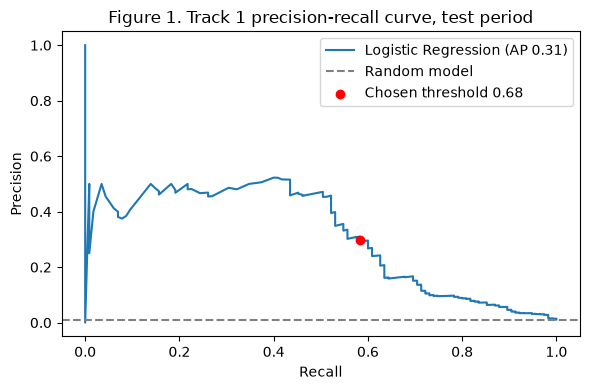

In [15]:
os.makedirs("../reports/figures", exist_ok=True)

pr_p, pr_r, _ = precision_recall_curve(test["High"], p_te)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(pr_r, pr_p, label=f"Logistic Regression (AP {average_precision_score(test['High'], p_te):.2f})")
ax.axhline(test["High"].mean(), color="grey", linestyle="--", label="Random model")
ax.scatter([recall_score(test["High"], pred)], [precision_score(test["High"], pred)],
           color="red", zorder=3, label=f"Chosen threshold {threshold:.2f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Figure 1. Track 1 precision-recall curve, test period")
ax.legend()
fig.tight_layout()
fig.savefig("../reports/figures/track1_precision_recall.png", dpi=150)
plt.show()

<details>
<summary><b>Code notes, line by line</b></summary>

- `pr_p, pr_r, _ = precision_recall_curve(test["High"], p_te)` : Test precision-recall curve.
- `ax.plot(pr_r, pr_p, ...)` : The curve, labelled with its average precision.
- `ax.axhline(test["High"].mean(), ...)` : A random model's precision (the base rate).
- `ax.scatter([recall], [precision], color="red")` : The chosen threshold's position.
- `fig.savefig("../reports/figures/track1_precision_recall.png", dpi=150)` : Saves the figure for the report.

</details>

**Result.** Figure 1 shows the trade-off behind Tables 9 and 10: precision falls steeply once recall passes about 0.6, and the chosen threshold (red point) sits at recall 0.58 and precision 0.30, far above the random model's precision of 0.011 (dashed line).

## 15. Save the model (local only)
`models/` is git-ignored, and the file holds asset codes from the confidential data: do not publish it.

In [16]:
os.makedirs("../models", exist_ok=True)
joblib.dump({"model": final, "features": set_b, "threshold": threshold,
             "target": "Priority in (1, 2)"}, "../models/track1_priority_lr.joblib")

['../models/track1_priority_lr.joblib']

<details>
<summary><b>Code notes, line by line</b></summary>

- `os.makedirs("../models", exist_ok=True)` : Creates the git-ignored models folder.
- `joblib.dump({"model": final, "features": set_b, "threshold": threshold, ...})` : Saves the pipeline with its feature list and threshold, so it can score new tickets later. Not for publishing (it contains asset codes).

</details>

On the current data, XGBoost and logistic regression perform the same within noise (CV average precision 0.455 against 0.451; test ROC-AUC 0.934 for both). Logistic regression is the chosen model because its coefficients explain each alert. XGBoost is the first alternative to re-test when more data arrives, because it can capture interactions such as asset type × time of day that the linear model misses.

## 16. Why recall fell from 0.70 (validation) to 0.58 (test)
Does refitting on October to January change recall, does recall differ between February and early March, and does the mix of High tickets change?

In [17]:
m_octdec = clone(fit_b[best_name].best_estimator_)
m_octdec.fit(fit_part[set_b].astype(str), fit_part["High"],
             clf__sample_weight=compute_sample_weight("balanced", fit_part["High"]))
p_m = m_octdec.predict_proba(test[set_b].astype(str))[:, 1]
pred_m = (p_m >= threshold).astype(int)
yt = test["High"].to_numpy()

print("Table 16. Why test recall is below validation recall")
tp_m = int(((yt == 1) & (pred_m == 1)).sum())
print("Oct-Dec model on test: alerts", int(pred_m.sum()), "| caught", tp_m, "of", int(yt.sum()), "| recall", round(tp_m / yt.sum(), 3))
tp_f = int(((yt == 1) & (pred == 1)).sum())
print("Final model on test   : alerts", int(pred.sum()), "| caught", tp_f, "of", int(yt.sum()), "| recall", round(tp_f / yt.sum(), 3))

for name, mask in [("Feb", test["Open_Time"] < "2014-03-01"), ("Mar 1-16", test["Open_Time"] >= "2014-03-01")]:
    mk = mask.to_numpy()
    tp = int(((yt[mk] == 1) & (pred[mk] == 1)).sum())
    print(name, "| High", int(yt[mk].sum()), "| caught", tp, "| recall", round(tp / yt[mk].sum(), 3), "| alerts", int(pred[mk].sum()))

allx = pd.concat([train, test])
h = allx[allx["High"] == 1].copy()
h["computer"] = h["CI_Cat"] == "computer"
print(h.groupby(h["Open_Time"].dt.to_period("M"))["computer"].agg(["size", "sum", "mean"]).round(2))

Table 16. Why test recall is below validation recall
Oct-Dec model on test: alerts 224 | caught 66 of 115 | recall 0.574
Final model on test   : alerts 225 | caught 67 of 115 | recall 0.583
Feb | High 79 | caught 45 | recall 0.57 | alerts 143
Mar 1-16 | High 36 | caught 22 | recall 0.611 | alerts 82
           size  sum  mean
Open_Time                 
2013-10     178  107  0.60
2013-11     133   81  0.61
2013-12     130   92  0.71
2014-01     100   65  0.65
2014-02      79   42  0.53
2014-03      36   20  0.56


<details>
<summary><b>Code notes, line by line</b></summary>

- `m_octdec = clone(...); m_octdec.fit(fit_part ...)` : The October-December model (the one the threshold was set on).
- `pred_m = (p_m >= threshold).astype(int)` : Its test alerts.
- `tp_m / tp_f` : Hits of that model against the final model: does refitting on January explain the drop?
- `for name, mask in [("Feb", ...), ("Mar 1-16", ...)]` : Recall in each test month.
- `allx = pd.concat([train, test]); h = allx[allx["High"] == 1]` : All High tickets.
- `h.groupby(month)["computer"].agg(["size", "sum", "mean"])` : Share of High tickets on computers per month: a mix change explains part of the gap.

</details>

**Result.** The October to December model catches 66 of 115 against 67 for the final model, so refitting is not the cause (Table 16, first two lines). Recall is 0.57 in February and 0.611 in early March. The computer share of High tickets falls from 0.65 in January to 0.53 to 0.56 in February and March (Table 16, last column), and the model is strongest on computer tickets (Table 11a): the asset mix explains part of the gap; the rest fits threshold optimism and noise.

## 17. Rolling-origin comparison
Four monthly folds (December, January, February, 1 to 16 March); each trains on everything before the month. Alerts are the top 2.2% of tickets (about 5 a day). Later decisions use these folds, not the test period.

In [18]:
def add_feats(d):
    d = d.copy()
    d["off_hours"] = ((d["hour"] < 8) | (d["hour"] >= 18)).astype(int).astype(str)
    d["is_weekend"] = (d["weekday"] >= 5).astype(int).astype(str)
    d["ci_time"] = d["CI_Cat"] + "|" + d["off_hours"] + d["is_weekend"]
    return d

eng_cols = set_b + ["off_hours", "is_weekend", "ci_time"]
full = add_feats(pd.concat([train, test]).sort_values("Open_Time").reset_index(drop=True))

folds = [("2013-12-01", "2014-01-01"), ("2014-01-01", "2014-02-01"),
         ("2014-02-01", "2014-03-01"), ("2014-03-01", "2014-03-17")]

xgb = lambda d, m: XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=d, min_child_weight=m,
                                 eval_metric="logloss", random_state=42, n_jobs=-1)
cands = {
    "LR, set B (current)": (set_b,    lambda: LogisticRegression(C=0.01, max_iter=2000)),
    "LR + time features":  (eng_cols, lambda: LogisticRegression(C=0.01, max_iter=2000)),
    "XGB + time features": (eng_cols, lambda: xgb(5, 5)),
    "XGB deeper":          (eng_cols, lambda: xgb(7, 10)),
}
ENS = "Average of LR and XGB (rank)"
BUDGET = 0.022   # alert on the top 2.2% of tickets, about 5 a day, like the chosen threshold

ap = {k: [] for k in list(cands) + [ENS]}
rc = {k: [] for k in ap}
for a, b in folds:
    tr = full[full["Open_Time"] < a]
    te = full[(full["Open_Time"] >= a) & (full["Open_Time"] < b)]
    ytr, yte = tr["High"], te["High"].to_numpy()
    w = compute_sample_weight("balanced", ytr)
    probs = {}
    for name, (cols, mk) in cands.items():
        m = make_pipe(cols, mk())
        m.fit(tr[cols].astype(str), ytr, clf__sample_weight=w)
        probs[name] = m.predict_proba(te[cols].astype(str))[:, 1]
    probs[ENS] = (pd.Series(probs["LR + time features"]).rank(pct=True)
                  + pd.Series(probs["XGB + time features"]).rank(pct=True)).to_numpy() / 2
    k = int(np.ceil(BUDGET * len(te)))
    for name, p in probs.items():
        ap[name].append(average_precision_score(yte, p))
        rc[name].append(yte[np.argsort(-p)[:k]].sum() / yte.sum())
    print(f"fold {a} to {b}: tickets {len(te)}, High {int(yte.sum())}, random AP {yte.mean():.4f}")

print("Table 17. Rolling-origin comparison over the four monthly folds")
print(pd.DataFrame({"mean AP": {k: np.mean(v) for k, v in ap.items()},
                    "min AP": {k: np.min(v) for k, v in ap.items()},
                    "mean recall at 2.2% alerts": {k: np.mean(v) for k, v in rc.items()}}).round(3))
print({k: np.round(v, 3).tolist() for k, v in ap.items()})

fold 2013-12-01 to 2014-01-01: tickets 6551, High 130, random AP 0.0198
fold 2014-01-01 to 2014-02-01: tickets 8049, High 100, random AP 0.0124
fold 2014-02-01 to 2014-03-01: tickets 7154, High 79, random AP 0.0110
fold 2014-03-01 to 2014-03-17: tickets 3075, High 36, random AP 0.0117
Table 17. Rolling-origin comparison over the four monthly folds
                              mean AP  min AP  mean recall at 2.2% alerts
LR, set B (current)             0.391   0.274                       0.613
LR + time features              0.392   0.273                       0.614
XGB + time features             0.402   0.300                       0.620
XGB deeper                      0.402   0.291                       0.627
Average of LR and XGB (rank)    0.402   0.281                       0.626
{'LR, set B (current)': [0.51, 0.41, 0.37, 0.274], 'LR + time features': [0.5, 0.421, 0.372, 0.273], 'XGB + time features': [0.466, 0.46, 0.381, 0.3], 'XGB deeper': [0.455, 0.466, 0.397, 0.291], 'Average of

<details>
<summary><b>Code notes, line by line</b></summary>

- `def add_feats(d):` : Adds off_hours, is_weekend and a CI_Cat x time interaction (ci_time) as text columns.
- `eng_cols = set_b + [...]` : Set B plus the three engineered columns.
- `full = add_feats(pd.concat([train, test]).sort_values("Open_Time")...)` : All labelled window tickets in time order.
- `folds = [("2013-12-01", "2014-01-01"), ...]` : Four monthly test folds; each trains on everything before it.
- `xgb = lambda d, m: XGBClassifier(...)` : Shortcut to build an XGBoost model with a given depth and child weight.
- `cands = {...}` : Candidates: current LR, LR + time features, XGB + time features, deeper XGB.
- `ENS / BUDGET = 0.022` : A rank-average ensemble, and an alert budget of 2.2% of tickets.
- `for a, b in folds: tr = full[< a]; te = full[a, b)` : Expanding training data, next month as test.
- `probs[ENS] = (rank(pct=True) + rank(pct=True)) / 2` : Averages the percentile ranks of the two models' scores.
- `k = ceil(BUDGET * len(te)); rc[name].append(yte[np.argsort(-p)[:k]].sum() / yte.sum())` : Recall within the alert budget.
- `pd.DataFrame({"mean AP", "min AP", "mean recall at 2.2% alerts"})` : Summary across the four folds.

</details>

**Result.** Mean average precision 0.391 for the headline model against 0.392 to 0.402 for the alternatives (time features, XGBoost, an ensemble), and mean recall at 2.2% alerts 0.613 against 0.614 to 0.627 (Table 17): all within noise. The fold-by-fold values (last line) cross over: XGBoost with time features wins January, February and March, logistic regression December. Logistic regression stays.

## 18. Sensitivity: CI_Name and the six unconfirmed-timing fields
Reassignments, related counts and KB_number may only be filled in after a ticket opens, so they are held out of the headline.
### 18a. Test-period comparison

In [19]:
variants = {
    "Set B (headline)": set_b,
    "Set B + CI_Name": set_b + ci_name,
    "Set B + unsure-timing fields": set_b + unsure_timing,
}

def tune_lr(cols):
    gs = GridSearchCV(make_pipe(cols, LogisticRegression(max_iter=2000)),
                      {"clf__C": [0.003, 0.01, 0.03, 0.1]},
                      cv=TimeSeriesSplit(n_splits=3), scoring="average_precision")
    gs.fit(train[cols].astype(str), y_train,
           clf__sample_weight=compute_sample_weight("balanced", y_train))
    return gs

rows = []
for name, cols in variants.items():
    gs = tune_lr(cols)
    pt = gs.best_estimator_.predict_proba(test[cols].astype(str))[:, 1]
    rows.append({"Features": name, "CV AP": round(gs.best_score_, 3),
                 "best C": gs.best_params_["clf__C"],
                 "Test AP": round(average_precision_score(test["High"], pt), 3),
                 "Test ROC-AUC": round(roc_auc_score(test["High"], pt), 3)})
print("Table 18a. CI_Name and the six unconfirmed-timing fields, test period")
print(pd.DataFrame(rows).to_string(index=False))

Table 18a. CI_Name and the six unconfirmed-timing fields, test period
                    Features  CV AP  best C  Test AP  Test ROC-AUC
            Set B (headline)  0.451    0.01    0.315         0.934
             Set B + CI_Name  0.452    0.03    0.319         0.936
Set B + unsure-timing fields  0.493    0.03    0.397         0.962


<details>
<summary><b>Code notes, line by line</b></summary>

- `variants = {...}` : Set B, Set B + CI_Name, Set B + the six unsure-timing fields.
- `def tune_lr(cols):` : Tunes only logistic regression's C with time-ordered CV and balanced weights.
- `for name, cols in variants.items(): ...` : For each variant: CV AP, best C, test AP and test ROC-AUC.

</details>

### 18b. The six fields on the rolling folds

In [20]:
cols_u = set_b + unsure_timing
res = []
for a, b in folds:
    tr = full[full["Open_Time"] < a]
    te = full[(full["Open_Time"] >= a) & (full["Open_Time"] < b)]
    m_six = make_pipe(cols_u, LogisticRegression(C=0.03, max_iter=2000))
    m_six.fit(tr[cols_u].astype(str), tr["High"],
              clf__sample_weight=compute_sample_weight("balanced", tr["High"]))
    res.append(average_precision_score(te["High"], m_six.predict_proba(te[cols_u].astype(str))[:, 1]))
print("Table 18b. Set B + six fields, AP per rolling fold (Dec, Jan, Feb, 1-16 Mar):", np.round(res, 3), "mean", round(np.mean(res), 3))

Table 18b. Set B + six fields, AP per rolling fold (Dec, Jan, Feb, 1-16 Mar): [0.549 0.503 0.436 0.368] mean 0.464


<details>
<summary><b>Code notes, line by line</b></summary>

- `cols_u = set_b + unsure_timing` : Set B plus the six fields.
- `for a, b in folds: ... m_six.fit(...)` : Same rolling folds as section 17.
- `res.append(average_precision_score(...))` : AP per fold, printed with the mean.

</details>

### 18c. The six fields at the headline alert volume (225), by asset segment

In [21]:
cols_u = set_b + unsure_timing
gs_u = tune_lr(cols_u)
p_u = gs_u.best_estimator_.predict_proba(test[cols_u].astype(str))[:, 1]
flag_u = topk_flag(p_u, 225 / len(test))
seg = np.where(test["CI_Cat"] == "computer", "computer", "other assets")
print("Table 18c. Set B + six fields at 225 alerts: High caught by asset segment")
for s in ["computer", "other assets"]:
    mk = seg == s
    print(s, "| High", int(yt[mk].sum()), "| caught", int(((yt[mk] == 1) & (flag_u[mk] == 1)).sum()))

Table 18c. Set B + six fields at 225 alerts: High caught by asset segment
computer | High 62 | caught 60
other assets | High 53 | caught 19


<details>
<summary><b>Code notes, line by line</b></summary>

- `gs_u = tune_lr(cols_u); p_u = ...` : Tuned model with the six fields and its test scores.
- `flag_u = topk_flag(p_u, 225 / len(test))` : The same 225 alerts as the headline model.
- `for s in ["computer", "other assets"]:` : High tickets caught in each asset segment.

</details>

**Result.** CI_Name adds nothing (test AP 0.319 against 0.315, Table 18a). The six fields lift test AP to 0.397 (Table 18a) and the rolling-fold mean to 0.464 against 0.391 (Table 18b against Table 17), and at 225 alerts catch 79 of 115 against 67 (Table 18c: other assets 19 of 53 against 7 in Table 11a). Not adopted until it is confirmed that they are known when a ticket opens.

## 19. Conclusion
- **Model:** logistic regression on asset and time fields (CI_Cat, CI_Subcat, WBS, Category, hour, weekday), threshold 0.678 (Table 6).
- **Result on the test period:** recall 0.583 (67 of 115, 95% interval about 0.49 to 0.67) and precision 0.298 at about 5 alerts a day (Tables 7a, 7b and 8); ROC-AUC 0.934, average precision 0.315 (28 times the base rate; Figure 1). It beats the "flag computer tickets" rule at every alert volume (Table 10).
- **Alternatives:** a tuned XGBoost performs equally well within noise (test AP 0.321, ROC-AUC 0.934; Table 4a, and Table 17 on rolling folds); logistic regression is kept as the simpler, explainable model, and XGBoost is the first alternative to re-test as more data arrives.
- **Operating point:** at the chosen threshold the desk would see 158 false alarms and miss 48 High tickets over the 44-day test period (Table 9); a lower threshold catches more (91 at 22.5 alerts a day) at a much higher alert load.
- **Priority for every ticket:** the four-class tagger in `09_track3_triage`, section 5, suggests P2 to P5; this model remains the P1/P2 alert.
- **Limits:** recall on non-computer tickets is 0.13 (Table 11a). Higher recall needs fields whose timing is unconfirmed (Tables 18a to 18c) or more history (Table A2).

## Appendix A. History features (not adopted)
Prior-ticket features for the same CI or WBS (recent ticket counts and a smoothed prior High rate), tested on the rolling folds. The gain rests mainly on the small March fold, so they should be re-tested with more data before adoption.
### A1. Build the features

In [22]:
full2 = full.copy()
for c in set_b:
    full2[c] = full2[c].astype(str)
tt = full2["Open_Time"].to_numpy()

def prior_count(key, hours):
    out = np.zeros(len(full2))
    for idx in full2.groupby(key).indices.values():
        t = tt[idx]
        left = np.searchsorted(t, t - np.timedelta64(hours, "h"), side="left")
        out[idx] = np.arange(len(idx)) - left
    return out

def prior_high_rate(key, a=20):
    g = full2.groupby(key)["High"]
    n_prior = g.cumcount()
    h_prior = g.cumsum() - full2["High"]
    base = full2["High"].expanding().mean().shift(1).fillna(full2["High"].mean())
    return ((h_prior + a * base) / (n_prior + a)).to_numpy()

full2["ci_n_7d"] = np.log1p(prior_count("CI_Name", 24 * 7))
full2["wbs_n_24h"] = np.log1p(prior_count("WBS", 24))
full2["ci_high_rate"] = prior_high_rate("CI_Name")
full2["wbs_high_rate"] = prior_high_rate("WBS")
print("Table A1. Range of the history features")
print(full2[["ci_n_7d", "wbs_n_24h", "ci_high_rate", "wbs_high_rate"]].describe().round(3).loc[["mean", "min", "max"]])

Table A1. Range of the history features
      ci_n_7d  wbs_n_24h  ci_high_rate  wbs_high_rate
mean    2.668      2.482         0.010          0.017
min     0.000      0.000         0.000          0.000
max     5.242      5.521         0.305          0.510


<details>
<summary><b>Code notes, line by line</b></summary>

- `full2 = full.copy(); full2[c] = full2[c].astype(str)` : A copy with text categories.
- `tt = full2["Open_Time"].to_numpy()` : Opening times as an array for fast search.
- `def prior_count(key, hours):` : For each ticket, the number of earlier tickets on the same key within the past `hours`.
- `np.searchsorted(t, t - np.timedelta64(hours, "h"), side="left")` : Position of the first ticket inside the look-back window; position minus that = earlier tickets in it.
- `def prior_high_rate(key, a=20):` : Smoothed High rate of the key using only earlier tickets.
- `g.cumcount(); g.cumsum() - High` : Earlier tickets and earlier High tickets for the key (the current ticket excluded).
- `base = expanding().mean().shift(1)` : The overall High rate so far, also from the past only.
- `(h_prior + a * base) / (n_prior + a)` : Shrinks rates of keys with few tickets towards the overall rate (a = 20 pseudo-tickets).
- `np.log1p(prior_count(...))` : Log of 1 + count, to tame large counts.
- `describe().loc[["mean", "min", "max"]]` : Quick range check of the new features.

</details>

### A2. Rolling-fold comparison

In [23]:
def make2(cat_cols, num_cols, C=0.01):
    enc = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30)
    parts = [("cat", enc, cat_cols)]
    if num_cols:
        parts.append(("num", StandardScaler(), num_cols))
    return Pipeline([("pre", ColumnTransformer(parts)), ("clf", LogisticRegression(C=C, max_iter=3000))])

def roll(num_cols):
    aps, rcs, rco, apo = [], [], [], []
    cols = set_b + num_cols
    for a, b in folds:
        tr = full2[full2["Open_Time"] < a]
        te = full2[(full2["Open_Time"] >= a) & (full2["Open_Time"] < b)]
        m = make2(set_b, num_cols)
        m.fit(tr[cols], tr["High"], clf__sample_weight=compute_sample_weight("balanced", tr["High"]))
        p = m.predict_proba(te[cols])[:, 1]
        y_ = te["High"].to_numpy()
        oth = (te["CI_Cat"] != "computer").to_numpy()
        flag = np.zeros(len(te), dtype=bool)
        flag[np.argsort(-p)[:int(np.ceil(0.022 * len(te)))]] = True
        aps.append(average_precision_score(y_, p))
        rcs.append(y_[flag].sum() / y_.sum())
        rco.append(y_[flag & oth].sum() / max(y_[oth].sum(), 1))
        apo.append(average_precision_score(y_[oth], p[oth]))
    return [float(np.mean(v)) for v in (aps, rcs, rco, apo)], np.round(aps, 3).tolist()

variants = {
    "Set B (should reproduce 0.391 / 0.613)": [],
    "+ recent tickets on same CI / WBS": ["ci_n_7d", "wbs_n_24h"],
    "+ prior High rate of CI / WBS": ["ci_high_rate", "wbs_high_rate"],
    "+ both": ["ci_n_7d", "wbs_n_24h", "ci_high_rate", "wbs_high_rate"],
}
res = {k: roll(v) for k, v in variants.items()}
print("Table A2. History features on the rolling folds")
print(pd.DataFrame({k: v[0] for k, v in res.items()},
                   index=["mean AP", "recall at 2.2% alerts", "recall, non-computer", "AP, non-computer"]).T.round(3))
print({k: v[1] for k, v in res.items()})

Table A2. History features on the rolling folds
                                        mean AP  recall at 2.2% alerts  recall, non-computer  AP, non-computer
Set B (should reproduce 0.391 / 0.613)    0.391                  0.613                 0.072             0.063
+ recent tickets on same CI / WBS         0.389                  0.623                 0.107             0.067
+ prior High rate of CI / WBS             0.414                  0.651                 0.183             0.142
+ both                                    0.416                  0.656                 0.190             0.142
{'Set B (should reproduce 0.391 / 0.613)': [0.51, 0.41, 0.37, 0.274], '+ recent tickets on same CI / WBS': [0.533, 0.409, 0.339, 0.274], '+ prior High rate of CI / WBS': [0.508, 0.446, 0.331, 0.374], '+ both': [0.514, 0.45, 0.324, 0.374]}


<details>
<summary><b>Code notes, line by line</b></summary>

- `def make2(cat_cols, num_cols, C=0.01):` : Pipeline with one-hot categories and standardised numeric features.
- `def roll(num_cols):` : Runs the four rolling folds with Set B plus the given history features.
- `oth = (te["CI_Cat"] != "computer")` : Non-computer tickets, the weak segment.
- `flag[np.argsort(-p)[:ceil(0.022 * len(te))]] = True` : Top 2.2% alerts.
- `aps, rcs, rco, apo` : AP, recall at 2.2%, recall on non-computer tickets, AP on non-computer tickets.
- `variants = {...}; res = {k: roll(v) ...}` : Set B alone and with each group of history features.
- `print(pd.DataFrame(...)); print({k: v[1] ...})` : Means across folds and AP per fold.

</details>

**Result.** Mean average precision 0.391 for Set B, 0.389 with recent-ticket counts, 0.414 with the prior High rate and 0.416 with both; recall on non-computer tickets rises from 0.072 to 0.190 (Table A2). The fold-by-fold values (last line of Table A2) show the first three folds tie; the gain comes from the 36-ticket March fold (0.274 to 0.374). Not adopted.